In [161]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Did you know? India is home to the world’s only **floating post office**! Located on Dal Lake in Srinagar, the “Bharat Post” service operates from a boat that delivers mail, parcels, and even offers a small souvenir shop—all while gently bobbing on the water. It’s a unique blend of tradition and ingenuity that’s become a popular tourist attraction and a quirky piece of India’s postal history. 🌊📬


## TOOLS

DuckDuckGo Search Tool

In [ ]:
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool


@tool
def search_duckduckgo(query: str) -> str:
    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun()
    return duck_search.invoke(query)


# result = search_duckduckgo.invoke({
#     "query": "latest AI news"
# })

# print(result)


Read full articles, watch videos, browse thousands of titles and more on the "Artificial intelligence" topic with Google News. 16 hours ago · Today's most important AI news, ranked and explained. Track artificial intelligence models, agents, funding, policy and research with updates throughout the day. Jun 11, 2016 · Read the latest on artificial intelligence and machine learning tech, the companies that are building them, and the ethical issues AI raises today. 6 days ago · Stay updated with the latest AI news, industry insights, top AI tools, model launches, reviews, and emerging technology trends at Times of AI. 16 hours ago · Read the latest AI news, model launches, policy updates, and industry analysis without hype. Clear, plain-English reporting from AI Understanding.


Arxiv Query Tool

In [163]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper
from langchain_core.tools import tool

# Initialize the wrapper and runner once outside the function
arxiv_wrapper = ArxivAPIWrapper(top_k_results=3, doc_content_chars_max=4000)
arxiv_query = ArxivQueryRun(api_wrapper=arxiv_wrapper)


@tool
def arxiv_tool(query: str) -> str:
    """This tool allows you to query the arXiv database for research papers."""
    return arxiv_query.invoke(query)


Wikipedia Search Tool

In [164]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_core.tools import tool

wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())


@tool
def wiki_tool(query: str) -> str:
  """Search Wikipedia for information on a given topic."""
  return wiki_query.invoke(query)


Custom Tool

In [165]:
@tool
def personal_info(name: str):

    """Use this tool to get personal information about Alice, Bob, or Charlie. 
    """

    info = {
        "Alice": "Alice is a software engineer with 5 years of experience in AI.",
        "Bob": "Bob is a data scientist who loves working with large datasets.",
        "Charlie": "Charlie is a product manager with a background in tech startups."
    }
    return info.get(name, "No information available for this person.")

TOOL BINDING

In [166]:
tools = [search_duckduckgo, arxiv_tool, wiki_tool, personal_info]

llm_with_tools = llm.bind_tools(tools)
llm_with_tools


response = llm_with_tools.invoke("What is the latest  news on Ai")
response.tool_calls

[{'name': 'search_duckduckgo',
  'args': {'query': 'latest AI news November 2026'},
  'id': 'fc_3926fe93-aecf-493d-ae4e-7dd98b53152e',
  'type': 'tool_call'}]

## LangGraph Creation    {ReAct Agent in LangGraph}

## Step 1 : define the Graph State


In [167]:
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import MessagesState

class graph_state(MessagesState):
    pass
    

## Step 2 : define the Graph Nodes 

In [168]:
from langchain_core.prompts import ChatPromptTemplate

def llm_node(state: graph_state):

    messages = state["messages"]

    prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a helpful assistant that can use the available tools to answer questions."
        ),
        ("placeholder", "{messages}")
    ])

    chain = prompt | llm_with_tools

    response = chain.invoke({
        "messages": messages
    })

    return {
        "messages": [response]
    }

## Tool call
## from langgraph.prebuilt import ToolNode   {in built}

i will create my custom TOol Node 


 ToolNode khud bana raha hai, instead of LangGraph ke predefined ToolNode.

 Aur iska purpose hai: LLM ne jo tool call request ki hai, usko actually execute karna aur result ko ToolMessage ke form mein State mein return karna.

 Chalo ekdum zero se samajhte hain. Abhi graph ya routing nahi, sirf ye function.
 1. Pehle samjho problem kya hai?
 Suppose user ne bola:
 What is 10 multiplied by 20?

 Tumne LLM ke saath tool bind kiya:
 llm_with_tools = llm.bind_tools(tools)



 LLM decide karta hai ki multiply tool call karna hai.

 LLM ek AIMessage return karta hai jiske andar tool_calls hota hai.

 Example:
 AIMessage(    content="",    tool_calls=[        {            "name": "multiply",            "args": {"a": 10, "b": 20},            "id": "call_123"        }    ])
 -->


 Notice karo: LLM ne multiplication nahi kiya. Usne sirf request bheji hai.

 Ab kisi ko actual multiplication execute karna padega.

 Wahi kaam tumhara custom tool_node() karega.


In [169]:
from langchain_core.messages import ToolMessage

def tool_node(state: graph_state) -> dict:

    messages = state["messages"]

    tools_by_name = {
        tool.name: tool for tool in tools
    } # Dictionary banana -> Jo bhi tools hain uski key: val form mein dictionary bananaraha tools_by_name = {
    # EX "multiply": multiply,
    # "add": add,
    # "divide": divide

#Why ? Taaki LLM jis tool ka naam return kare, hum us tool ko easily find kar sakein.

    tool_results = [] #Is list mein hum executed tools ke results store karenge.

    for tool_call in messages[-1].tool_calls:
    # - messages[-1] = Conversation ka last message.
    # - .tool_calls = AI ne jo tool calls request ki hain.
    # - for = Har tool call ko ek-ek karke process karna.

        tool = tools_by_name[tool_call["name"]]  #Actual tool find karna

        observation = tool.invoke(  #actual tool milgya execute karna 
            tool_call["args"]
        )

            #Tool execute ho gaya aur result 200 mila.Lekin ye result conversation history mein bhi add karna hai.Isliye ToolMessage banate hain.
        tool_results.append(      # Tool Message bananan 
            ToolMessage(
                content=str(observation),
                tool_call_id=tool_call["id"]
            )
        )

    return {"messages": tool_results}

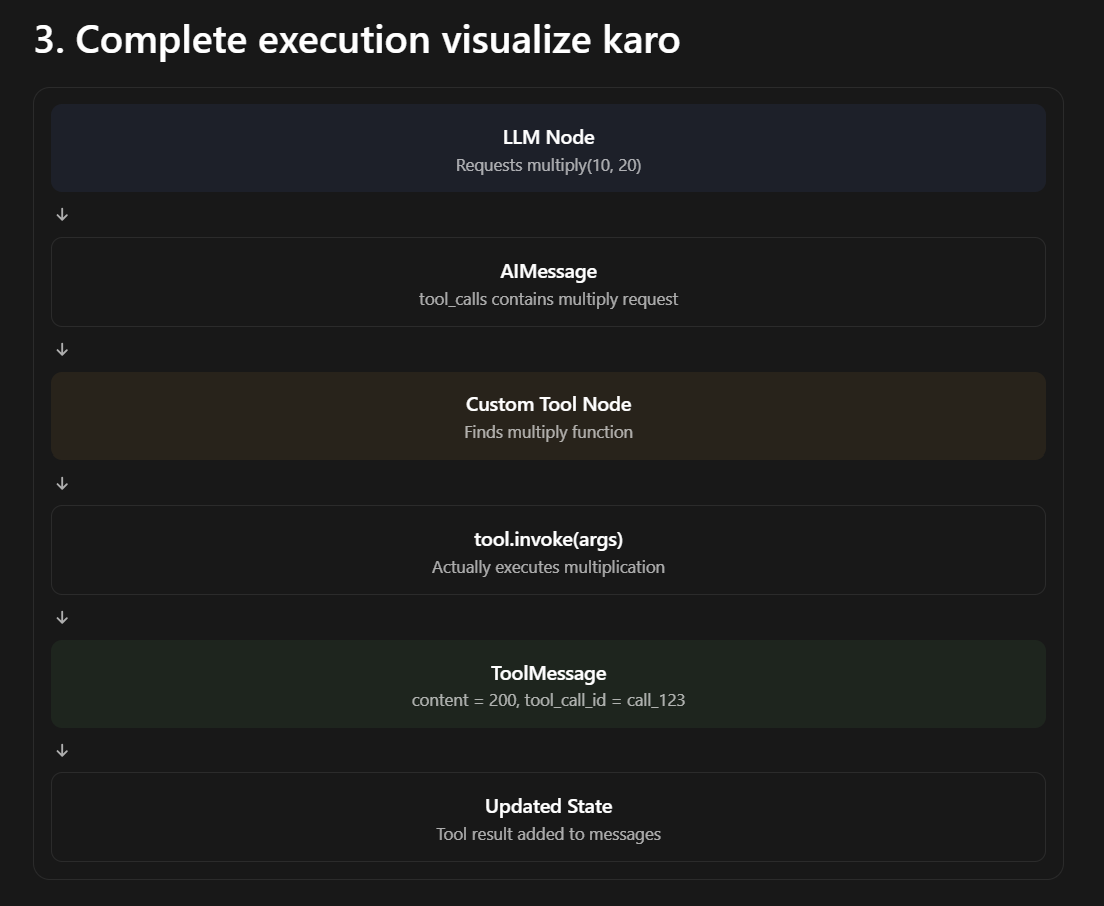

# create conditionmal Edge Function

In [170]:
from langgraph.graph import END

def if_tool_call(state:graph_state)->str:
    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_call"
    else:
        return END

# Create State Graph 


In [171]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_state)

# Add nodes
graph.add_node("LLM_Node", llm_node)
graph.add_node("Tool_Node", tool_node)

# Define edges
graph.add_edge(START, "LLM_Node")

graph.add_conditional_edges(
    "LLM_Node",
    if_tool_call,
    {
        "tool_call": "Tool_Node",
        END: END
    }
)

# After tool execution, go back to LLM
graph.add_edge("Tool_Node", "LLM_Node")

# Compile
react_graph = graph.compile()

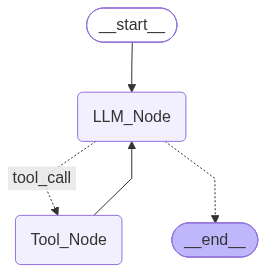

In [172]:
from IPython.display import display, Markdown, Image

display(Image(react_graph.get_graph().draw_mermaid_png()))


## Graph Invocation

In [173]:
from langchain_core.messages import HumanMessage

result = react_graph.invoke({
    "messages": [
        HumanMessage(
            content="What is the latest news on AI?"
        )
    ]
})

print(result["messages"][-1].content)

DDGSException: DNSError: DNSError('error sending request for url (https://wt.wikipedia.org/w/api.php?action=opensearch&profile=fuzzy&limit=1&search=latest%20AI%20news) > error resolving DNS > DNS error: no records found for Query { name: Name("wt.wikipedia.org."), query_type: A, query_class: IN }')